# 2.2 — Shortlist validation: redundancy, stability & robustness

**Goal**: take the frozen shortlist and confirm it is ready for Fase 3 — that the candidates
don't **repeat signal** (redundancy), are **stable over time** (PSI / IV-per-vintage), aren't
**leaking**, and that the ranking **survives de-duplication** (weighting). Output: a green-lit
final shortlist plus any drop / down-weight decisions.

**Input**: `data/interim/applications.parquet` (1.1) + the tuned `references/bin_spec.yaml`
(2.0) + `credit_policy`. All signal is on the labeled `Contratado` sample — the
**selection-bias caveat applies to every number here**.

**Shortlist** (`credit_policy.VAR_SELECTION`, single source of truth): `classe_social`,
`Capacidade Financeira`, `score_klavi_2`, `status_empregaticio`. **`regiao` is excluded on
fairness grounds** (region proxies protected attributes → redlining risk).

**Convention**: WoE = `ln(%goods/%bads)`, **positive = safer**; 0.5 smoothing.

## 1. Setup & load

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR / "src"))
from credit_policy import woe, binning, VAR_SELECTION   # noqa: E402

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

app = pd.read_parquet(PROJECT_DIR / "data" / "interim" / "applications.parquet")
spec = binning.load_spec(PROJECT_DIR / "references" / "bin_spec.yaml")

lab = app[app["OVER30M2"].notna()].copy()
y = lab["OVER30M2"].astype(int)
safras = sorted(lab["SAFRA"].unique())
binned = {v: binning.apply_spec(lab[v], spec[v]) for v in VAR_SELECTION}

print(f"labeled sample: {len(lab):,}  |  bads: {y.sum():,} ({y.mean():.2%})  |  safras: "
      f"{safras[0]}–{safras[-1]}")
print("shortlist:", VAR_SELECTION)

labeled sample: 24,148  |  bads: 2,488 (10.30%)  |  safras: 202406–202506
shortlist: ['classe_social', 'Capacidade Financeira', 'score_klavi_2', 'status_empregaticio']


## 2. Redundancy — WoE correlation

WoE-encode each candidate (`woe.woe_encode`: per-row log-odds) and correlate — this asks whether
two variables *order risk the same way*, which is exactly the redundancy the scorecard would
double-count. Two matrices side by side:
- **naive** — Pearson over all rows, `(missing)` WoE included;
- **overlap-only** — pairwise Pearson on rows where **both** variables are observed (bin ≠
  `(missing)`) — the honest read.

Because missingness is *shared* across Klavi variables (a no-snapshot application is missing on
all of them), the naive matrix is inflated by co-missingness, not real signal overlap; the
co-missingness table below shows that separately. Rule of thumb: |r| ≳ 0.5 → keep the higher-IV /
better-coverage variable, drop or down-weight the other.

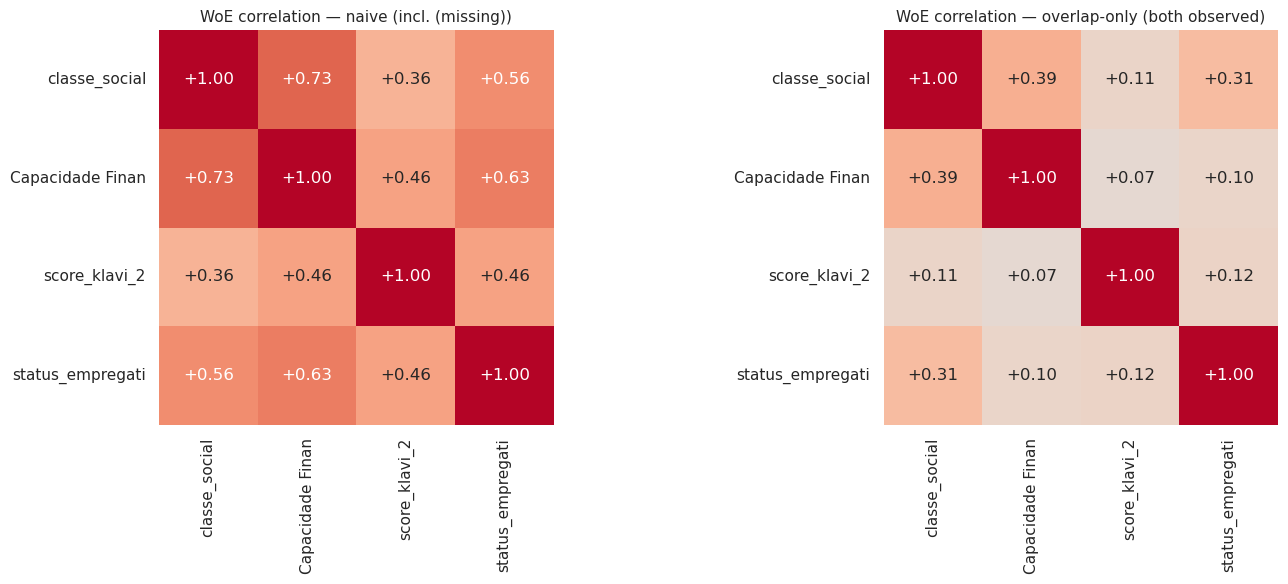

In [2]:
W = woe.woe_frame(binned, y)                                   # per-row WoE, one column per var
notmiss = pd.DataFrame({v: binned[v].astype(object).ne("(missing)") for v in VAR_SELECTION})

R_naive = W.corr()
R_over = pd.DataFrame(index=VAR_SELECTION, columns=VAR_SELECTION, dtype=float)
N_over = pd.DataFrame(index=VAR_SELECTION, columns=VAR_SELECTION, dtype=int)
for a in VAR_SELECTION:
    for b in VAR_SELECTION:
        m = notmiss[a] & notmiss[b]
        R_over.loc[a, b] = W.loc[m, a].corr(W.loc[m, b])
        N_over.loc[a, b] = int(m.sum())

short = [v[:16] for v in VAR_SELECTION]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (R, title) in zip(axes, [(R_naive, "naive (incl. (missing))"),
                                 (R_over, "overlap-only (both observed)")]):
    sns.heatmap(R.astype(float), ax=ax, vmin=-1, vmax=1, cmap="coolwarm", center=0,
                annot=True, fmt="+.2f", square=True, cbar=False,
                xticklabels=short, yticklabels=short)
    ax.set_title(f"WoE correlation — {title}", fontsize=11)
plt.tight_layout()
plt.show()

In [3]:
# Overlap sample size per pair, and shared-missingness (share of rows missing on BOTH).
comiss = pd.DataFrame(
    {a: {b: float(((~notmiss[a]) & (~notmiss[b])).mean()) for b in VAR_SELECTION}
     for a in VAR_SELECTION})
print("overlap n (both observed):"); print(N_over.to_string())
print("\nco-missingness (share of rows missing on both):"); print(comiss.round(2).to_string())

overlap n (both observed):
                       classe_social  Capacidade Financeira  score_klavi_2  status_empregaticio
classe_social                12442.0                11008.0        11089.0              12318.0
Capacidade Financeira        11008.0                11008.0         9788.0              10974.0
score_klavi_2                11089.0                 9788.0        11089.0              10976.0
status_empregaticio          12318.0                10974.0        10976.0              12318.0

co-missingness (share of rows missing on both):
                       classe_social  Capacidade Financeira  score_klavi_2  status_empregaticio
classe_social                   0.48                   0.48           0.48                 0.48
Capacidade Financeira           0.48                   0.54           0.49                 0.49
score_klavi_2                   0.48                   0.49           0.54                 0.49
status_empregaticio             0.48                   0.49 

**Key takeaway**: co-missingness inflates the naive view — `classe_social` × `Capacidade
Financeira` reads **0.73** naively but only **0.39** on the overlap (both observed), and
`Capacidade Financeira` × `status_empregaticio` collapses **0.63 → 0.10**. On the honest
overlap-only view **every pair is |r| < 0.4** (max `classe_social` × `Capacidade Financeira`
+0.39 — both socioeconomic/financial; all others ≤ 0.31). No pair crosses the ~0.5 redundancy
line → **keep all four**; they carry complementary signal, and the shared missingness is the
`has_snapshot` story (handled separately), not double-counted signal.

## 3. Stability — PSI + IV per vintage

Two questions per variable across `SAFRA`: (a) does the **population** shift — PSI of the bin
distribution each safra vs the pooled reference (< 0.1 stable / 0.1–0.25 moderate / > 0.25
significant); (b) does the **signal** hold — IV computed within each safra.

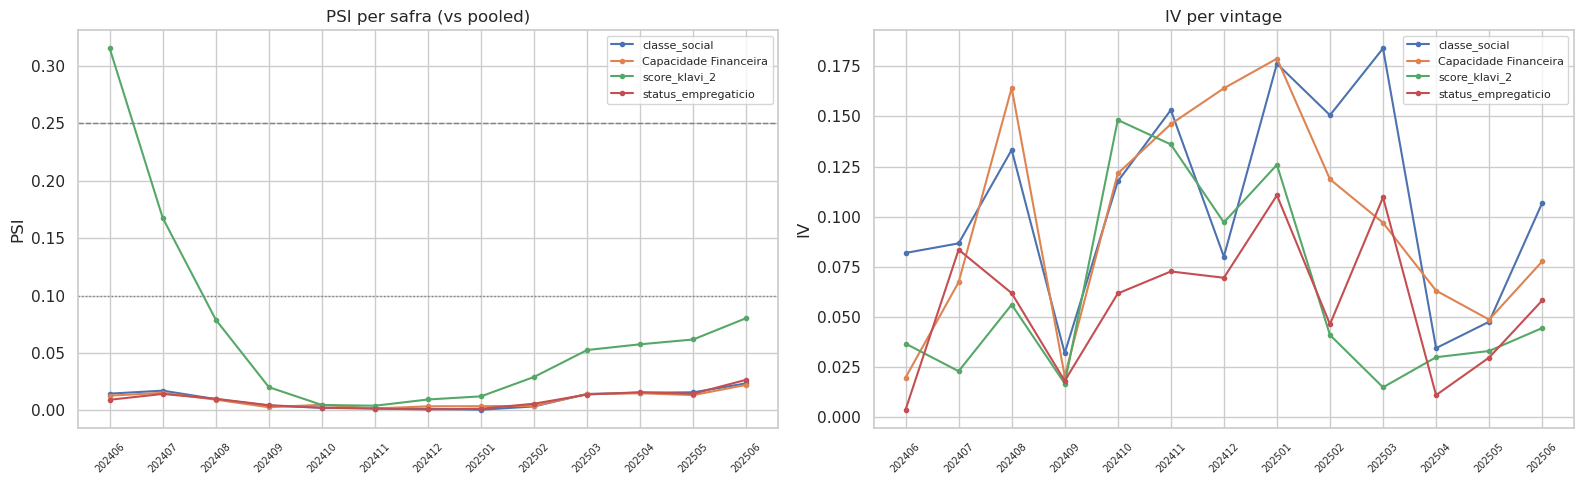

,PSI_max,PSI_mean,IV_min,IV_mean,IV_max
classe_social,0.024,0.010,0.032,0.106,0.184
Capacidade Financeira,0.022,0.009,0.020,0.099,0.179
score_klavi_2,0.315,0.069,0.015,0.062,0.148
status_empregaticio,0.027,0.009,0.004,0.057,0.111


In [4]:
psi_df = pd.DataFrame(
    {v: {sf: woe.psi(binned[v].value_counts(),
                     binned[v][(lab["SAFRA"] == sf).values].value_counts())
         for sf in safras} for v in VAR_SELECTION}).T
iv_df = pd.DataFrame(
    {v: {sf: woe.iv_of(woe.woe_table(binned[v][(lab["SAFRA"] == sf).values],
                                     y[(lab["SAFRA"] == sf).values]))
         for sf in safras} for v in VAR_SELECTION}).T

x = [str(s) for s in safras]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for v in VAR_SELECTION:
    axes[0].plot(x, psi_df.loc[v], marker="o", ms=3, label=v)
    axes[1].plot(x, iv_df.loc[v], marker="o", ms=3, label=v)
for thr, ls in [(0.1, ":"), (0.25, "--")]:
    axes[0].axhline(thr, color="0.5", lw=1, ls=ls)
axes[0].set_title("PSI per safra (vs pooled)"); axes[0].set_ylabel("PSI")
axes[1].set_title("IV per vintage"); axes[1].set_ylabel("IV")
for ax in axes:
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.concat({"PSI_max": psi_df.max(axis=1), "PSI_mean": psi_df.mean(axis=1),
           "IV_min": iv_df.min(axis=1), "IV_mean": iv_df.mean(axis=1),
           "IV_max": iv_df.max(axis=1)}, axis=1).round(3)

**Key takeaway**: three of four are stable — PSI max ≈ 0.02–0.03 (well under 0.1) with steady
within-vintage IV. **`score_klavi_2` is the exception**: PSI peaks at **0.31** in one vintage
(> 0.25 = significant population shift), and its within-vintage IV swings (~0.02–0.15) — though on
~18-bads/bin cohorts that scatter is largely sampling noise, not lost signal (formal test in
`references/woe-bin-significance-testing.md`). The old middle cut was not significant even pooled,
so its bins were **coarsened to 3 monotone** (`≤484 | 484–603 | >603`), which resolves the earlier
WoE-crossing; what remains is genuine **population drift**. Verdict: `score_klavi_2` **stays,
flagged "watch"** — add a recency guard for that drift before Fase 3 leans hard on it; the other
three are safe to use as-is.

## 4. Leakage screen

Light, point-in-time sanity pass: nothing should be suspiciously predictive. The features are
Klavi snapshots taken at the application date (`REFERENCIA = DATA`, established in 1.0/1.1), so
they are point-in-time by construction.

In [5]:
leak = pd.DataFrame({
    "IV": {v: woe.iv_of(woe.woe_table(binned[v], y)) for v in VAR_SELECTION},
    "max_abs_woe": {v: woe.woe_table(binned[v], y).query("n > 0")["woe"].abs().max()
                    for v in VAR_SELECTION},
})
leak["verdict"] = leak["IV"].map(woe.iv_verdict)
leak.round(4).sort_values("IV", ascending=False)

,IV,max_abs_woe,verdict
classe_social,0.0890,0.4686,weak
Capacidade Financeira,0.0669,0.5100,weak
score_klavi_2,0.0345,0.7185,weak
status_empregaticio,0.0313,0.4814,weak


**Key takeaway**: no leakage signal — every candidate is **weak-tier (IV < 0.1)**, nowhere near
the > 0.5 "too good to be true" zone, and no single bin has an extreme WoE (max |WoE| < 1).
Combined with the point-in-time snapshot construction, the shortlist passes.

## 5. Weighting sensitivity — one row per `uuid`

1.2 flagged that at grain `(uuid, DATA)` a heavy re-applicant is over-represented in IV/WoE.
Re-compute IV on a de-duplicated sample (most-recent application per `uuid`) and check the
ranking is unchanged.

In [6]:
dedup = lab.sort_values("DATA").drop_duplicates("uuid", keep="last")
yd = dedup["OVER30M2"].astype(int)
binned_d = {v: binning.apply_spec(dedup[v], spec[v]) for v in VAR_SELECTION}

cmp = pd.DataFrame({
    "IV_all": {v: woe.iv_of(woe.woe_table(binned[v], y)) for v in VAR_SELECTION},
    "IV_dedup": {v: woe.iv_of(woe.woe_table(binned_d[v], yd)) for v in VAR_SELECTION},
})
cmp["delta"] = cmp["IV_dedup"] - cmp["IV_all"]
print(f"n_all = {len(lab):,}   n_dedup = {len(dedup):,}   "
      f"({len(lab) - len(dedup):,} re-applicant rows dropped)")
cmp.round(4).sort_values("IV_all", ascending=False)

n_all = 24,148   n_dedup = 23,299   (849 re-applicant rows dropped)


,IV_all,IV_dedup,delta
classe_social,0.0890,0.0901,0.0012
Capacidade Financeira,0.0669,0.0673,0.0004
score_klavi_2,0.0345,0.0350,0.0005
status_empregaticio,0.0313,0.0310,-0.0003


**Key takeaway**: de-duplicating to one (most-recent) application per `uuid` drops only **849 of
24,148** labeled rows (re-applicants are few among `Contratado`). IV moves by **< 0.0012** for
every variable and the **ranking order is unchanged** — the over-representation flagged in 1.2
does not move the shortlist. No weighting needed.

## 6. Final shortlist & decisions

**Final shortlist for Fase 3**: `classe_social`, `Capacidade Financeira`, `score_klavi_2`,
`status_empregaticio`.

| check | result |
|---|---|
| **Redundancy** (§2) | overlap-only |r| < 0.4 for every pair → no double-counting; keep all four |
| **Stability** (§3) | populations stable (PSI < 0.03) except **`score_klavi_2`** (PSI 0.31 population drift; bins coarsened to 3 monotone) → *watch* |
| **Leakage** (§4) | all IV < 0.1, |WoE| < 1, point-in-time by construction → pass |
| **Weighting** (§5) | dedup Δ IV < 0.0012, ranking unchanged → robust |

The four split into a **socioeconomic block** (`classe_social`, `status_empregaticio`) and a
**financial block** (`Capacidade Financeira`, `score_klavi_2`) with only mild cross-correlation —
complementary, as a policy wants. `regiao` remains excluded on fairness grounds.

**Carry to Fase 3**: `score_klavi_2` bins already coarsened to 3 monotone (the finer split was not
statistically significant); keep a recency guard for its residual population drift. Hold the
conservative-opening stance given the rising vintage default rate (1.0 §4).

## 7. Plain-language summary

This notebook had one job: we already had **four finalist variables** (`classe_social`,
`Capacidade Financeira`, `score_klavi_2`, `status_empregaticio`), and before building a policy on
them we wanted to be sure they're trustworthy. So we ran four sanity checks.

**1. Are any two variables secretly saying the same thing? (Redundancy — §2)**
The worry: if two variables carry the same information, using both just double-counts it. What we
found: they're all genuinely different — the strongest overlap (`classe_social` × `Capacidade
Financeira`) was mild (0.39, under the 0.5 "too similar" line). We avoided a trap: naively these
two *look* similar (0.73), but that's fake — they're just **missing on the same people**. Comparing
only people where both are present, the fake similarity vanishes. **→ Keep all four; they
complement each other** (two describe social/employment, two describe finances).

**2. Do the variables behave consistently over time? (Stability — §3)**
The worry: a variable that predicts well this year but not next is dangerous to build on. What we
found: three of four are rock-solid across the 13 months. **The exception is `score_klavi_2`** — its
applicant mix drifted in one period. We simplified its score bands into three cleanly-ordered
groups (the finer four-band split wasn't statistically real) and **flagged it "watch"**: keep it,
but keep an eye on that drift when building the score.

**3. Is any variable "too good to be true"? (Leakage — §4)**
The worry: a variable can predict suspiciously well because it accidentally contains information
from *after* the decision — which you wouldn't have in real life. What we found: no problem — all
four are modest predictors, and by design they're snapshots taken *at application time*. **Clean.**

**4. Do repeat applicants distort the picture? (Weighting — §5)**
The worry: people who applied several times count multiple times and could skew results. What we
found: it barely matters — only 849 of ~24,000 rows are repeats, and removing them changed nothing.
**Robust.**

**Bottom line:** all four variables passed and move forward to the policy stage (Fase 3). The only
asterisk is `score_klavi_2` — keep an eye on it. Separately, `regiao` was deliberately left out
earlier on fairness grounds (region can proxy for race/class).